In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/content/region_month.csv")
df.head()

,country,iso3,region_code,region_name,month,conflict_events,conflict_deaths,civilian_deaths,events_state,deaths_state,...,price_sorghum,n_markets_cowpeas,n_markets_maize,n_markets_millet,n_markets_rice_imported,n_markets_rice_local,n_markets_sorghum,fao_food_index,fao_cereals_index,fao_oils_index
0,Burkina Faso,BFA,BF13,Centre,2015-01,0,0,0,0,0,...,184.0,1,2,2,0,0,2,101.0,105.9,95.00
1,Burkina Faso,BFA,BF13,Centre,2015-02,0,0,0,0,0,...,181.5,1,2,2,0,0,2,98.7,101.6,95.18
2,Burkina Faso,BFA,BF13,Centre,2015-03,0,0,0,0,0,...,173.0,0,2,2,0,0,2,95.7,99.5,92.62
3,Burkina Faso,BFA,BF13,Centre,2015-04,0,0,0,0,0,...,171.0,1,2,2,0,0,2,94.6,98.2,91.87
4,Burkina Faso,BFA,BF13,Centre,2015-05,0,0,0,0,0,...,173.0,2,2,2,0,0,2,95.0,95.7,94.49


In [2]:

print("Rows and columns:", df.shape)

print(df.columns.tolist())

Rows and columns: (8040, 36)
['country', 'iso3', 'region_code', 'region_name', 'month', 'conflict_events', 'conflict_deaths', 'civilian_deaths', 'events_state', 'deaths_state', 'events_nonstate', 'deaths_nonstate', 'events_onesided', 'deaths_onesided', 'rain_mm', 'rain_anomaly_mm', 'rain_pct_normal', 'prev_rainy_season_pct_normal', 'ch_share_phase35', 'ch_season', 'ch_proj_share_phase35', 'price_cowpeas', 'price_maize', 'price_millet', 'price_rice_imported', 'price_rice_local', 'price_sorghum', 'n_markets_cowpeas', 'n_markets_maize', 'n_markets_millet', 'n_markets_rice_imported', 'n_markets_rice_local', 'n_markets_sorghum', 'fao_food_index', 'fao_cereals_index', 'fao_oils_index']


In [3]:
cols = [
    "country",
    "region_name",
    "month",
    "rain_mm",
    "prev_rainy_season_pct_normal",
    "price_millet"
]

# Display sample observations
print(df[cols].head(15))

# Check missing values
print("\nMissing values:")
print(df[cols].isna().sum())

# Check date range
print("\nDate range:")
print(df["month"].min(), "to", df["month"].max())

# Check number of countries and regions
print("\nCountries:", df["country"].nunique())
print("Regions:", df["region_name"].nunique())

         country region_name    month  rain_mm  prev_rainy_season_pct_normal  \
0   Burkina Faso      Centre  2015-01      0.0                         107.4   
1   Burkina Faso      Centre  2015-02      0.3                         107.4   
2   Burkina Faso      Centre  2015-03      6.3                         107.4   
3   Burkina Faso      Centre  2015-04      5.4                         107.4   
4   Burkina Faso      Centre  2015-05     31.0                         107.4   
5   Burkina Faso      Centre  2015-06    106.7                         107.4   
6   Burkina Faso      Centre  2015-07    230.3                         107.4   
7   Burkina Faso      Centre  2015-08    247.3                         107.4   
8   Burkina Faso      Centre  2015-09    188.3                         107.4   
9   Burkina Faso      Centre  2015-10     30.0                         120.1   
10  Burkina Faso      Centre  2015-11      1.0                         120.1   
11  Burkina Faso      Centre  2015-12   

In [4]:
# Missing millet prices by country
missing_country = (
    df.groupby("country")["price_millet"]
      .apply(lambda x: x.isna().sum())
)

print(missing_country)

country
Burkina Faso       0
Chad            1182
Mali             143
Niger             15
Senegal           63
Name: price_millet, dtype: int64


In [5]:
# Available millet prices by country
available_country = (
    df.groupby("country")["price_millet"]
      .count()
)

print(available_country)

country
Burkina Faso    1560
Chad            1578
Mali             937
Niger            945
Senegal         1617
Name: price_millet, dtype: int64


In [6]:
print(df["price_millet"].describe())

count    6637.000000
mean      258.841733
std        79.791452
min        65.500000
25%       201.000000
50%       244.500000
75%       297.000000
max       932.000000
Name: price_millet, dtype: float64


In [8]:
import pandas as pd, numpy as np
p='/content/region_month.csv'
df=pd.read_csv(p)
df.shape, df.columns.tolist()



((8040, 36),
 ['country',
  'iso3',
  'region_code',
  'region_name',
  'month',
  'conflict_events',
  'conflict_deaths',
  'civilian_deaths',
  'events_state',
  'deaths_state',
  'events_nonstate',
  'deaths_nonstate',
  'events_onesided',
  'deaths_onesided',
  'rain_mm',
  'rain_anomaly_mm',
  'rain_pct_normal',
  'prev_rainy_season_pct_normal',
  'ch_share_phase35',
  'ch_season',
  'ch_proj_share_phase35',
  'price_cowpeas',
  'price_maize',
  'price_millet',
  'price_rice_imported',
  'price_rice_local',
  'price_sorghum',
  'n_markets_cowpeas',
  'n_markets_maize',
  'n_markets_millet',
  'n_markets_rice_imported',
  'n_markets_rice_local',
  'n_markets_sorghum',
  'fao_food_index',
  'fao_cereals_index',
  'fao_oils_index'])

In [9]:
df.loc[df.price_millet.idxmax(), ['country','region_name','month','price_millet','n_markets_millet']], df.groupby('country').agg(total=('price_millet','size'), available=('price_millet','count'), missing=('price_millet',lambda s:s.isna().sum()))



(country                Chad
 region_name           Kanem
 month               2024-09
 price_millet          932.0
 n_markets_millet          1
 Name: 2276, dtype: object,
               total  available  missing
 country                                
 Burkina Faso   1560       1560        0
 Chad           2760       1578     1182
 Mali           1080        937      143
 Niger           960        945       15
 Senegal        1680       1617       63)

In [10]:
region_quality = (
    df.groupby(["country", "region_name"])
    .agg(
        total_months=("price_millet", "size"),
        available_prices=("price_millet", "count")
    )
    .reset_index()
)

region_quality["coverage_pct"] = (
    region_quality["available_prices"] /
    region_quality["total_months"] * 100
)

# Display regions with lowest price coverage
print(
    region_quality.sort_values("coverage_pct")
    .head(15)
    .to_string(index=False)
)

country       region_name  total_months  available_prices  coverage_pct
   Chad            Borkou           120                 0      0.000000
   Chad    Mayo Kebbi Est           120                 0      0.000000
   Chad        Ennedi-Est           120                 0      0.000000
   Chad  Mayo-Kebbi Ouest           120                 0      0.000000
   Chad           Mandoul           120                 0      0.000000
   Chad      Ennedi Ouest           120                 0      0.000000
   Chad           Tibesti           120                 0      0.000000
   Chad          Tandjile           120                 0      0.000000
   Mali             Kidal           120                 0      0.000000
   Chad   Logone Oriental           120                83     69.166667
   Chad       Moyen-Chari           120                99     82.500000
   Chad Logone Occidental           120               101     84.166667
   Chad           Salamat           120               104     86

In [11]:
# Keep regions with at least 80% millet price coverage
valid_regions = region_quality[
    region_quality["coverage_pct"] >= 80
].copy()

# Display the retained regions
print(valid_regions.to_string(index=False))

print("\nTotal valid regions:", len(valid_regions))

     country       region_name  total_months  available_prices  coverage_pct
Burkina Faso Boucle du Mouhoun           120               120    100.000000
Burkina Faso          Cascades           120               120    100.000000
Burkina Faso            Centre           120               120    100.000000
Burkina Faso        Centre-Est           120               120    100.000000
Burkina Faso       Centre-Nord           120               120    100.000000
Burkina Faso      Centre-Ouest           120               120    100.000000
Burkina Faso        Centre-Sud           120               120    100.000000
Burkina Faso               Est           120               120    100.000000
Burkina Faso     Hauts-Bassins           120               120    100.000000
Burkina Faso              Nord           120               120    100.000000
Burkina Faso   Plateau Central           120               120    100.000000
Burkina Faso             Sahel           120               120    100.000000

In [12]:
# Filter the original dataset
df_valid = df.merge(
    valid_regions[["country", "region_name"]],
    on=["country", "region_name"],
    how="inner"
)

print("Filtered dataset:", df_valid.shape)

Filtered dataset: (6840, 36)


In [13]:
# Convert month into datetime
df_valid["month_date"] = pd.to_datetime(df_valid["month"])

df_valid["year"] = df_valid["month_date"].dt.year
df_valid["month_number"] = df_valid["month_date"].dt.month

# Extract October rainfall information
rainy_season = df_valid[
    df_valid["month_number"] == 10
][
    ["country", "region_name", "year",
     "prev_rainy_season_pct_normal"]
].copy()

print(rainy_season.head())

         country region_name  year  prev_rainy_season_pct_normal
9   Burkina Faso      Centre  2015                         120.1
21  Burkina Faso      Centre  2016                         122.2
33  Burkina Faso      Centre  2017                          87.1
45  Burkina Faso      Centre  2018                         109.8
57  Burkina Faso      Centre  2019                         100.8


In [14]:
annual_prices = (
    df_valid.groupby(
        ["country", "region_name", "year"]
    )
    .agg(
        avg_millet_price=("price_millet", "mean"),
        available_months=("price_millet", "count")
    )
    .reset_index()
)

print(annual_prices.head())

        country        region_name  year  avg_millet_price  available_months
0  Burkina Faso  Boucle du Mouhoun  2015        150.666667                12
1  Burkina Faso  Boucle du Mouhoun  2016        154.916667                12
2  Burkina Faso  Boucle du Mouhoun  2017        178.791667                12
3  Burkina Faso  Boucle du Mouhoun  2018        188.750000                12
4  Burkina Faso  Boucle du Mouhoun  2019        136.083333                12


In [15]:
annual_prices = annual_prices.sort_values(
    ["country", "region_name", "year"]
)

annual_prices["next_year_price_change_pct"] = (
    annual_prices.groupby(
        ["country", "region_name"]
    )["avg_millet_price"]
    .transform(lambda x: x.shift(-1).div(x).sub(1).mul(100))
)

print(annual_prices.head(15))

         country        region_name  year  avg_millet_price  available_months  \
0   Burkina Faso  Boucle du Mouhoun  2015        150.666667                12   
1   Burkina Faso  Boucle du Mouhoun  2016        154.916667                12   
2   Burkina Faso  Boucle du Mouhoun  2017        178.791667                12   
3   Burkina Faso  Boucle du Mouhoun  2018        188.750000                12   
4   Burkina Faso  Boucle du Mouhoun  2019        136.083333                12   
5   Burkina Faso  Boucle du Mouhoun  2020        165.291667                12   
6   Burkina Faso  Boucle du Mouhoun  2021        193.666667                12   
7   Burkina Faso  Boucle du Mouhoun  2022        298.666667                12   
8   Burkina Faso  Boucle du Mouhoun  2023        267.500000                12   
9   Burkina Faso  Boucle du Mouhoun  2024        300.333333                12   
10  Burkina Faso           Cascades  2015        204.416667                12   
11  Burkina Faso           C

In [16]:
print("Available months per region-year:")
print(annual_prices["available_months"].value_counts().sort_index())

print("\nRegion-years with fewer than 9 months:")
print(
    annual_prices[
        annual_prices["available_months"] < 9
    ][["country", "region_name", "year", "available_months"]]
)

Available months per region-year:
available_months
3       7
4       2
5       2
6       5
7       1
9      17
10     22
11     63
12    451
Name: count, dtype: int64

Region-years with fewer than 9 months:
     country        region_name  year  available_months
140     Chad              Batha  2015                 3
150     Chad     Chari-Baguirmi  2015                 3
170     Chad       Hadjer-Lamis  2015                 3
190     Chad                Lac  2015                 3
206     Chad  Logone Occidental  2021                 4
208     Chad  Logone Occidental  2023                 6
216     Chad        Moyen-Chari  2021                 5
218     Chad        Moyen-Chari  2023                 6
219     Chad        Moyen-Chari  2024                 4
229     Chad          N'Djamena  2024                 7
240     Chad            Salamat  2015                 3
250     Chad               Sila  2015                 3
260     Chad          Wadi Fira  2015                 3
437  Sene

In [17]:
analysis_df = rainy_season.merge(
    annual_prices,
    on=["country", "region_name", "year"],
    how="inner"
)

# Remove 2024 because we do not have 2025 price data
analysis_df = analysis_df[
    analysis_df["year"] < 2024
]

print(analysis_df.head())
print("Final shape:", analysis_df.shape)

        country region_name  year  prev_rainy_season_pct_normal  \
0  Burkina Faso      Centre  2015                         120.1   
1  Burkina Faso      Centre  2016                         122.2   
2  Burkina Faso      Centre  2017                          87.1   
3  Burkina Faso      Centre  2018                         109.8   
4  Burkina Faso      Centre  2019                         100.8   

   avg_millet_price  available_months  next_year_price_change_pct  
0        211.875000                12                   -0.963618  
1        209.833333                12                   19.956315  
2        251.708333                12                    5.545439  
3        265.666667                12                  -17.738394  
4        218.541667                12                    7.893232  
Final shape: (513, 7)


In [18]:
analysis_df = analysis_df[
    analysis_df["available_months"] >= 9
].copy()

print("Shape after filtering:", analysis_df.shape)
print(analysis_df["available_months"].value_counts().sort_index())

Shape after filtering: (498, 7)
available_months
9      17
10     20
11     50
12    411
Name: count, dtype: int64


In [19]:
correlation = analysis_df[
    ["prev_rainy_season_pct_normal",
     "next_year_price_change_pct"]
].corr()

print(correlation)

                              prev_rainy_season_pct_normal  \
prev_rainy_season_pct_normal                      1.000000   
next_year_price_change_pct                       -0.095541   

                              next_year_price_change_pct  
prev_rainy_season_pct_normal                   -0.095541  
next_year_price_change_pct                      1.000000  


In [20]:
print(
    analysis_df[
        ["prev_rainy_season_pct_normal",
         "next_year_price_change_pct"]
    ].describe()
)

       prev_rainy_season_pct_normal  next_year_price_change_pct
count                    498.000000                  498.000000
mean                     109.385743                    7.933908
std                       14.954923                   21.392334
min                       61.400000                  -36.696624
25%                      100.625000                   -6.145183
50%                      107.800000                    5.713223
75%                      117.675000                   17.731365
max                      169.200000                   83.333333


In [22]:
country_corr = (
    analysis_df.groupby("country")
    .apply(
        lambda x: x["prev_rainy_season_pct_normal"].corr(
            x["next_year_price_change_pct"]
        ),
        include_groups=False
    )
)

print(country_corr)

country
Burkina Faso   -0.175950
Chad            0.096480
Mali           -0.394636
Niger          -0.056853
Senegal        -0.148497
dtype: float64


In [23]:
country_summary = (
    analysis_df.groupby("country")
    .agg(
        observations=("next_year_price_change_pct", "count"),
        avg_rainfall=("prev_rainy_season_pct_normal", "mean"),
        avg_price_change=("next_year_price_change_pct", "mean")
    )
    .reset_index()
)

country_summary["correlation"] = (
    analysis_df.groupby("country")
    .apply(
        lambda x: x["prev_rainy_season_pct_normal"].corr(
            x["next_year_price_change_pct"]
        ),
        include_groups=False
    )
    .values
)

print(country_summary)


        country  observations  avg_rainfall  avg_price_change  correlation
0  Burkina Faso           117    108.649573          9.513358    -0.175950
1          Chad           115    114.694783          6.969155     0.096480
2          Mali            72    106.412500          9.225520    -0.394636
3         Niger            72    107.144444          7.480396    -0.056853
4       Senegal           122    108.164754          6.833972    -0.148497


In [24]:
mali_data = analysis_df[
    analysis_df["country"] == "Mali"
].copy()

print("Largest price increases:")
print(
    mali_data.nlargest(
        5, "next_year_price_change_pct"
    )[
        ["region_name", "year",
         "prev_rainy_season_pct_normal",
         "next_year_price_change_pct"]
    ]
)

print("\nLargest price decreases:")
print(
    mali_data.nsmallest(
        5, "next_year_price_change_pct"
    )[
        ["region_name", "year",
         "prev_rainy_season_pct_normal",
         "next_year_price_change_pct"]
    ]
)


Largest price increases:
    region_name  year  prev_rainy_season_pct_normal  \
296     Sikasso  2021                         103.3   
306       Segou  2021                          93.3   
346      Bamako  2021                         111.2   
316       Mopti  2021                          97.0   
286   Koulikoro  2021                         101.6   

     next_year_price_change_pct  
296                   83.035852  
306                   79.050591  
346                   77.201288  
316                   75.780432  
286                   75.159398  

Largest price decreases:
    region_name  year  prev_rainy_season_pct_normal  \
303       Segou  2018                         116.1   
307       Segou  2022                         116.8   
297     Sikasso  2022                         107.0   
293     Sikasso  2018                         116.3   
317       Mopti  2022                         112.0   

     next_year_price_change_pct  
303                  -28.326267  
307            

In [25]:
mali_2021 = mali_data[
    mali_data["year"] == 2021
].sort_values(
    "next_year_price_change_pct",
    ascending=False
)

print(
    mali_2021[
        ["region_name",
         "prev_rainy_season_pct_normal",
         "avg_millet_price",
         "next_year_price_change_pct"]
    ].to_string(index=False)
)

region_name  prev_rainy_season_pct_normal  avg_millet_price  next_year_price_change_pct
    Sikasso                         103.3        202.510417                   83.035852
      Segou                          93.3        186.958333                   79.050591
     Bamako                         111.2        220.041667                   77.201288
      Mopti                          97.0        198.875000                   75.780432
  Koulikoro                         101.6        204.218750                   75.159398
 Tombouctou                          88.5        238.083333                   64.683234
        Gao                          90.8        250.000000                   52.583333
      Kayes                         105.7        286.750000                   44.245859


In [26]:
year_2021 = analysis_df[
    analysis_df["year"] == 2021
]

country_2021 = (
    year_2021.groupby("country")
    .agg(
        regions=("region_name", "count"),
        avg_rainfall=("prev_rainy_season_pct_normal", "mean"),
        avg_price_change=("next_year_price_change_pct", "mean")
    )
    .reset_index()
)

print(country_2021)

        country  regions  avg_rainfall  avg_price_change
0  Burkina Faso       13    105.653846         51.449926
1          Chad       12    103.791667         11.167023
2          Mali        8     98.925000         68.967498
3         Niger        8    104.787500          8.756517
4       Senegal       13    110.876923         47.008698


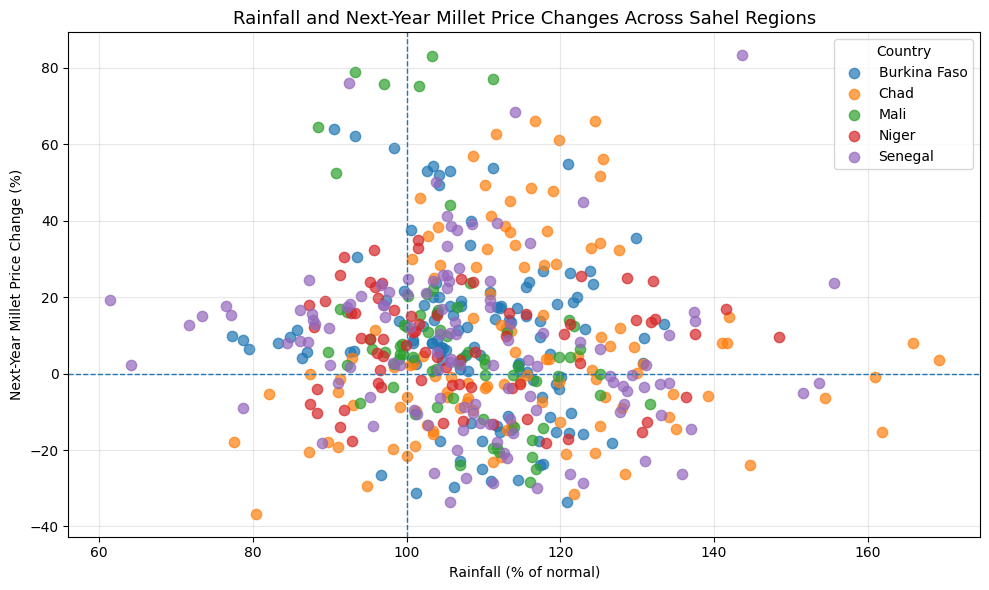

In [27]:
# Create the figure
plt.figure(figsize=(10, 6))

# Plot one group for each country
for country, group in analysis_df.groupby("country"):
    plt.scatter(
        group["prev_rainy_season_pct_normal"],
        group["next_year_price_change_pct"],
        label=country,
        alpha=0.7,
        s=55
    )

# Reference lines
plt.axhline(y=0, linestyle="--", linewidth=1)
plt.axvline(x=100, linestyle="--", linewidth=1)

# Labels and title
plt.title(
    "Rainfall and Next-Year Millet Price Changes Across Sahel Regions",
    fontsize=13
)
plt.xlabel("Rainfall (% of normal)")
plt.ylabel("Next-Year Millet Price Change (%)")

# Legend and grid
plt.legend(title="Country")
plt.grid(alpha=0.3)

# Display chart
plt.tight_layout()
plt.show()

In [28]:
analysis_df["rainfall_category"] = np.where(
    analysis_df["prev_rainy_season_pct_normal"] < 90,
    "Dry",
    np.where(
        analysis_df["prev_rainy_season_pct_normal"] <= 110,
        "Normal",
        "Wet"
    )
)

print(analysis_df["rainfall_category"].value_counts())

rainfall_category
Normal    235
Wet       224
Dry        39
Name: count, dtype: int64


/tmp/ipykernel_1456/3727815748.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


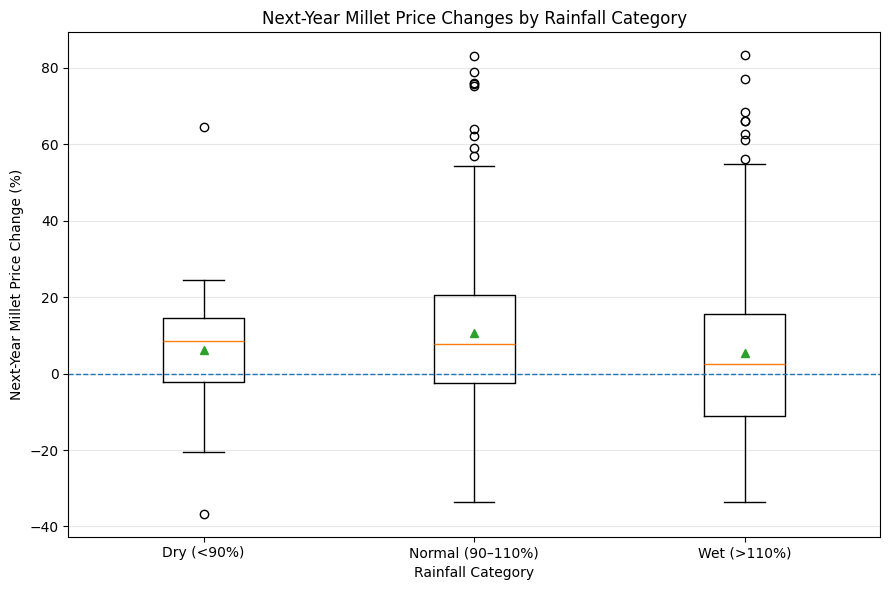

In [29]:
# Prepare the price changes for each category
dry = analysis_df[
    analysis_df["rainfall_category"] == "Dry"
]["next_year_price_change_pct"]

normal = analysis_df[
    analysis_df["rainfall_category"] == "Normal"
]["next_year_price_change_pct"]

wet = analysis_df[
    analysis_df["rainfall_category"] == "Wet"
]["next_year_price_change_pct"]

# Create box plot
plt.figure(figsize=(9, 6))

plt.boxplot(
    [dry, normal, wet],
    labels=["Dry (<90%)", "Normal (90–110%)", "Wet (>110%)"],
    showmeans=True
)

plt.axhline(y=0, linestyle="--", linewidth=1)

plt.title("Next-Year Millet Price Changes by Rainfall Category")
plt.xlabel("Rainfall Category")
plt.ylabel("Next-Year Millet Price Change (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()